# Phase 6: Customer Churn Prediction Using Machine Learning

## 1. Introduction

Customer churn prediction uses machine learning to identify customers who are likely to stop using a service.

In this phase, we will use the feature-engineered Netflix customer dataset to train machine learning models that predict whether a customer will churn.

## 2. Objectives

- Load and inspect the feature-engineered dataset.
- Separate input features and the churn target.
- Prepare numerical and categorical variables.
- Split the data into training and testing sets.
- Train multiple machine learning classification models.
- Evaluate model performance using appropriate metrics.
- Identify the most useful features for predicting customer churn.

## 3. Machine Learning Models

The following classification algorithms will be explored:

- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier

## 4. Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC Score

In [1]:
import pandas as pd
import numpy as np

# Load feature-engineered dataset
df = pd.read_csv("/content/netflix_feature_engineered.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (8000, 36)


,customer_id,age,gender,country,acquisition_channel,customer_segment,preferred_language,plan_id,subscription_start_date,monthly_price,...,average_support_satisfaction,unique_issue_categories,feedback_count,average_feedback_rating,negative_feedback_count,positive_feedback_count,churned,has_viewing_activity,has_support_tickets,has_feedback
0,CUST000744,21.0,Female,United Kingdom,Organic Search,Individual,English,PLAN03,2019-06-03,22.99,...,3.0,0.0,1.0,3.0,0.0,0.0,0,1,0,1
1,CUST001502,31.0,Male,Canada,Referral,Family,French,PLAN01,2026-01-13,6.99,...,3.0,0.0,0.0,3.0,0.0,0.0,0,1,0,0
2,CUST005383,40.0,Male,United Kingdom,Paid Social,Student,English,PLAN01,2023-06-17,6.99,...,3.0,0.0,1.0,4.0,0.0,1.0,0,1,0,1
3,CUST004708,27.0,Male,United Kingdom,Partner Bundle (Telecom),Individual,Hindi,PLAN02,2019-03-09,15.49,...,3.0,0.0,0.0,3.0,0.0,0.0,1,1,0,0
4,CUST005877,36.0,Male,Indonesia,Email Campaign,Student,French,PLAN03,2025-12-03,22.99,...,3.0,0.0,0.0,3.0,0.0,0.0,0,1,0,0


In [2]:
# Check dataset information
print("DATASET INFORMATION")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate customer IDs:")
print(df["customer_id"].duplicated().sum())

print("\nChurn distribution:")
print(df["churned"].value_counts())

print("\nChurn percentage:")
print(df["churned"].value_counts(normalize=True) * 100)

print("\nNumerical feature summary:")
display(df.describe())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 36 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    8000 non-null   object 
 1   age                            8000 non-null   float64
 2   gender                         8000 non-null   object 
 3   country                        8000 non-null   object 
 4   acquisition_channel            8000 non-null   object 
 5   customer_segment               8000 non-null   object 
 6   preferred_language             8000 non-null   object 
 7   plan_id                        8000 non-null   object 
 8   subscription_start_date        8000 non-null   object 
 9   monthly_price                  8000 non-null   float64
 10  auto_renew                     8000 non-null   bool   
 11  subscription_tenure_days       8000 non-null   int64  
 12  payment_count               

,age,monthly_price,subscription_tenure_days,payment_count,failed_payment_count,average_payment_amount,total_payment_amount,payment_failure_rate,viewing_sessions,total_watch_minutes,...,average_support_satisfaction,unique_issue_categories,feedback_count,average_feedback_rating,negative_feedback_count,positive_feedback_count,churned,has_viewing_activity,has_support_tickets,has_feedback
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,...,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,32.532625,13.424625,1269.216125,13.703750,0.890125,13.741879,188.432959,0.065795,7.607375,375.847125,...,3.109246,0.677125,0.603375,3.079679,0.172375,0.239250,0.248875,0.981000,0.528625,0.430000
std,10.531265,6.124100,789.748589,3.344045,1.017685,6.601749,103.577415,0.085037,3.750364,214.989076,...,0.694043,0.766453,0.845815,0.788744,0.439529,0.510188,0.432388,0.136533,0.499211,0.495107
min,2.000000,6.990000,0.000000,1.000000,0.000000,5.242500,6.990000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,25.000000,6.990000,575.000000,15.000000,0.000000,6.990000,104.850000,0.000000,5.000000,230.000000,...,3.000000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,32.000000,15.490000,1247.000000,15.000000,1.000000,15.490000,206.910000,0.066667,8.000000,370.000000,...,3.000000,1.000000,0.000000,3.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
75%,39.000000,15.490000,1938.000000,15.000000,1.000000,15.490000,232.350000,0.111111,10.000000,499.250000,...,3.000000,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
max,76.000000,22.990000,2737.000000,15.000000,8.000000,67.123333,629.930000,1.000000,21.000000,2291.000000,...,5.000000,5.000000,7.000000,5.000000,4.000000,4.000000,1.000000,1.000000,1.000000,1.000000


## 3. Dataset Inspection and Initial Analysis

### Objective
To understand the structure, quality, and target distribution of the feature-engineered dataset before machine learning.

### Key Findings
- Total records: 8,000 customers.
- Total columns: 36.
- Missing values: 0.
- Duplicate customer IDs: 0.
- Non-churned customers: 6,009 (75.11%).
- Churned customers: 1,991 (24.89%).

### Interpretation
The dataset contains numerical, categorical, Boolean, and date variables. The churn target is moderately imbalanced because non-churned customers represent approximately 75% of the records.

### Conclusion
The dataset passed the initial inspection and is suitable for machine learning preparation. Stratified sampling and multiple evaluation metrics will be used to account for the class imbalance.

In [3]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(
    columns=["customer_id", "subscription_start_date", "churned"]
)

y = df["churned"]

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical features:", categorical_features)
print("\nNumerical feature count:", len(numerical_features))

print("\nTarget distribution:")
print(y.value_counts())

Input feature shape: (8000, 33)
Target shape: (8000,)

Categorical features: ['gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language', 'plan_id', 'auto_renew']

Numerical feature count: 26

Target distribution:
churned
0    6009
1    1991
Name: count, dtype: int64


## 4. Feature and Target Separation

### Objective
To separate the input variables from the target variable before training machine learning models.

### Process
- Selected `churned` as the target variable.
- Removed `customer_id` because it is an identifier and does not provide useful predictive information.
- Removed `subscription_start_date` because subscription duration is already represented by `subscription_tenure_days`.
- Identified categorical and numerical features.

### Results
- Input features: 33
- Categorical features: 7
- Numerical features: 26
- Target variable: `churned`

### Conclusion
The input features and target variable were successfully separated. The dataset is ready for the training and testing split.

In [4]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

Training feature shape: (6400, 33)
Testing feature shape: (1600, 33)

Training target distribution:
churned
0    4807
1    1593
Name: count, dtype: int64
churned
0    75.109375
1    24.890625
Name: proportion, dtype: float64

Testing target distribution:
churned
0    1202
1     398
Name: count, dtype: int64
churned
0    75.125
1    24.875
Name: proportion, dtype: float64


## 5. Training and Testing Data Split

### Objective
To divide the dataset into training and testing sets for machine learning.

### Methodology
- Training data: 80% (6,400 records).
- Testing data: 20% (1,600 records).
- Random state: 42.
- Stratified sampling was used to preserve the target class distribution.

### Results
The training set contains 75.11% non-churned and 24.89% churned customers. The testing set contains 75.13% non-churned and 24.88% churned customers.

### Conclusion
The stratified split successfully maintained a similar churn distribution in both datasets. The training data is ready for model development, while the testing data will be used for final evaluation.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Preprocess categorical and numerical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

Preprocessing pipeline created successfully!
Categorical features: 7
Numerical features: 26


## 6. Data Preprocessing

### Objective
To prepare categorical and numerical features for machine learning.

### Methodology
- One-Hot Encoding was selected for the 7 categorical features to convert categories into numerical values.
- Standard Scaling was selected for the 26 numerical features to bring them to a comparable scale.
- `handle_unknown="ignore"` was used to handle categories that may appear in testing data but not in training data.
- A ColumnTransformer was created to apply the appropriate preprocessing to each feature group.

### Conclusion
The preprocessing pipeline was created successfully. It will be fitted on training data only to help prevent data leakage during preprocessing.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Define machine learning models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# Create a separate preprocessing and model pipeline for each model
pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

print("Three machine learning pipelines created successfully!")

for name in pipelines:
    print("-", name)

Three machine learning pipelines created successfully!
- Logistic Regression
- Decision Tree
- Random Forest


In [7]:
# Train all three machine learning models

for name, pipeline in pipelines.items():
    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)
    print(f"{name} trained successfully!\n")

print("All models have been trained successfully!")

Training Logistic Regression...
Logistic Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!

All models have been trained successfully!


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, pipeline in pipelines.items():

    # Predict churn labels
    y_pred = pipeline.predict(X_test)

    # Predict churn probabilities
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Display model comparison
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7231,0.4633,0.7136,0.5618,0.7891
2,Random Forest,0.7875,0.6208,0.3744,0.4671,0.7772
1,Decision Tree,0.6994,0.3965,0.3995,0.3980,0.5991


## 7. Machine Learning Model Evaluation

### Objective
To compare the performance of Logistic Regression, Decision Tree, and Random Forest models.

### Evaluation Metrics
Accuracy, precision, recall, F1-score, and ROC-AUC were used to evaluate the models.

### Results
- Logistic Regression achieved 72.31% accuracy, 71.36% recall, 56.18% F1-score, and 78.91% ROC-AUC.
- Random Forest achieved the highest accuracy (78.75%) and precision (62.08%).
- Decision Tree achieved 69.94% accuracy and 59.91% ROC-AUC.

### Interpretation
Logistic Regression identified a larger proportion of actual churned customers than the other models. Random Forest produced more precise churn predictions but missed more actual churners.

### Conclusion
Logistic Regression is the current leading model because it achieved the highest recall, F1-score, and ROC-AUC. Further evaluation using confusion matrices and classification reports will help assess its performance in more detail.


Logistic Regression

Classification Report:
              precision    recall  f1-score   support

 Not Churned       0.88      0.73      0.80      1202
     Churned       0.46      0.71      0.56       398

    accuracy                           0.72      1600
   macro avg       0.67      0.72      0.68      1600
weighted avg       0.78      0.72      0.74      1600



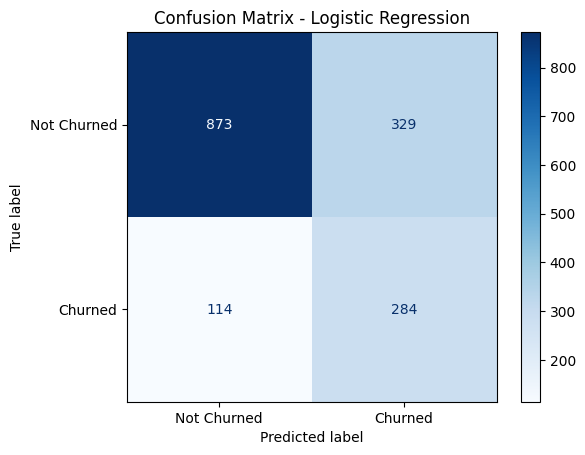


Decision Tree

Classification Report:
              precision    recall  f1-score   support

 Not Churned       0.80      0.80      0.80      1202
     Churned       0.40      0.40      0.40       398

    accuracy                           0.70      1600
   macro avg       0.60      0.60      0.60      1600
weighted avg       0.70      0.70      0.70      1600



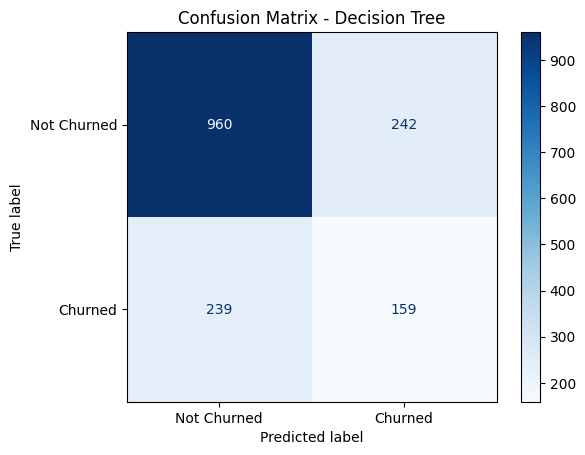


Random Forest

Classification Report:
              precision    recall  f1-score   support

 Not Churned       0.82      0.92      0.87      1202
     Churned       0.62      0.37      0.47       398

    accuracy                           0.79      1600
   macro avg       0.72      0.65      0.67      1600
weighted avg       0.77      0.79      0.77      1600



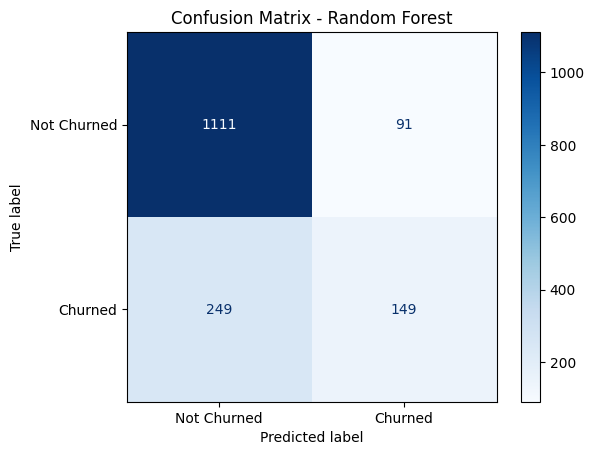

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

for name, pipeline in pipelines.items():

    y_pred = pipeline.predict(X_test)

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Not Churned", "Churned"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Not Churned", "Churned"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

## 8. Classification Reports and Model Analysis

### Objective
To understand how accurately each model identifies churned and non-churned customers.

### Key Findings
- Logistic Regression achieved 71% recall and 46% precision for the churn class.
- Random Forest achieved 62% churn precision but only 37% churn recall.
- Decision Tree achieved approximately 40% churn precision and recall.
- Logistic Regression achieved the highest churn F1-score of approximately 56%.

### Interpretation
Logistic Regression identifies a larger proportion of actual churned customers. Random Forest is more precise when predicting churn but misses more actual churners. Decision Tree has weaker churn detection performance.

### Conclusion
Logistic Regression is selected as the current leading model because identifying more customers at risk of leaving is an important business objective. Further threshold analysis may help improve the balance between precision and recall.

In [10]:
from sklearn.metrics import confusion_matrix

for name, pipeline in pipelines.items():

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    tn, fp, fn, tp = cm.ravel()

    print("\n", name)
    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)


 Logistic Regression
True Negatives: 873
False Positives: 329
False Negatives: 114
True Positives: 284

 Decision Tree
True Negatives: 960
False Positives: 242
False Negatives: 239
True Positives: 159

 Random Forest
True Negatives: 1111
False Positives: 91
False Negatives: 249
True Positives: 149


## 9. Confusion Matrix Analysis

### Objective
To examine the correct and incorrect predictions made by each classification model.

### Results

**Logistic Regression**
- True Positives: 284
- True Negatives: 873
- False Positives: 329
- False Negatives: 114

**Decision Tree**
- True Positives: 159
- True Negatives: 960
- False Positives: 242
- False Negatives: 239

**Random Forest**
- True Positives: 149
- True Negatives: 1,111
- False Positives: 91
- False Negatives: 249

### Interpretation
Logistic Regression correctly identified the highest number of churned customers (284) and had the fewest missed churners (114). Random Forest produced fewer false alarms but missed 249 actual churners.

### Conclusion
Logistic Regression is the strongest model for churn identification among the three models tested. Its higher recall makes it more useful for a retention strategy focused on identifying customers at risk of leaving.

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get churn probabilities from Logistic Regression
logistic_model = pipelines["Logistic Regression"]

y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Test different probability thresholds
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:

    y_threshold_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_threshold_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.30,0.3556,0.8819,0.5069
1,0.35,0.3782,0.8467,0.5229
2,0.40,0.4095,0.8015,0.5421
3,0.45,0.4341,0.7613,0.5529
4,0.50,0.4633,0.7136,0.5618
5,0.55,0.4916,0.6608,0.5638
6,0.60,0.5284,0.6080,0.5654


## 10. Prediction Threshold Optimization

### Objective
To examine how changing the classification threshold affects churn prediction performance.

### Methodology
The Logistic Regression model's predicted churn probabilities were evaluated at thresholds from 0.30 to 0.60.

### Key Findings
- Threshold 0.30 achieved the highest recall of 88.19%.
- Threshold 0.60 achieved the highest F1-score of 56.54%.
- At threshold 0.60, precision was 52.84% and recall was 60.80%.
- Increasing the threshold generally improved precision while reducing recall.

### Interpretation
A lower threshold identifies more potential churners but creates more false alarms. A higher threshold produces more selective predictions but may miss additional customers who churn.

### Conclusion
A threshold of 0.60 is selected as the current balanced option because it achieved the highest F1-score among the tested thresholds. A lower threshold may be preferred when the business prioritizes identifying as many churn-risk customers as possible.

Final Logistic Regression Model
Selected Threshold: 0.6

Confusion Matrix:
[[986 216]
 [156 242]]

Classification Report:
              precision    recall  f1-score   support

 Not Churned       0.86      0.82      0.84      1202
     Churned       0.53      0.61      0.57       398

    accuracy                           0.77      1600
   macro avg       0.70      0.71      0.70      1600
weighted avg       0.78      0.77      0.77      1600



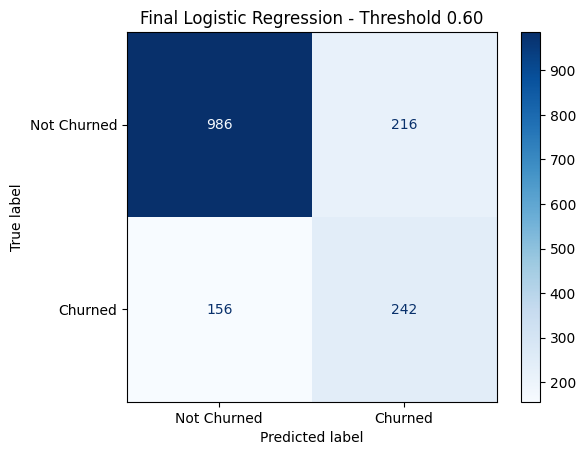

In [12]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Selected threshold
best_threshold = 0.60

# Generate predictions using selected threshold
y_final_pred = (y_prob >= best_threshold).astype(int)

# Confusion matrix
cm = confusion_matrix(y_test, y_final_pred)

print("Final Logistic Regression Model")
print("Selected Threshold:", best_threshold)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_final_pred,
    target_names=["Not Churned", "Churned"],
    zero_division=0
))

# Visualize confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_final_pred,
    display_labels=["Not Churned", "Churned"],
    cmap="Blues"
)

plt.title("Final Logistic Regression - Threshold 0.60")
plt.show()

## 11. Final Logistic Regression Model Evaluation

### Objective
To evaluate the selected Logistic Regression model using the optimized probability threshold of 0.60.

### Results
- Accuracy: 77%
- Churn precision: 53%
- Churn recall: 61%
- Churn F1-score: 57%

### Confusion Matrix
- True Negatives: 986
- False Positives: 216
- False Negatives: 156
- True Positives: 242

### Interpretation
The final model correctly identified 242 of the 398 actual churned customers in the test dataset. It missed 156 churned customers and incorrectly flagged 216 non-churned customers.

### Conclusion
The Logistic Regression model with a 0.60 threshold was selected as the final model among the three tested approaches. It provides a balance between identifying churned customers and limiting false alarms. Its performance should be interpreted with the dataset's same-day activity timing limitation in mind.

In [13]:
# Extract trained Logistic Regression model
logistic_pipeline = pipelines["Logistic Regression"]

# Get transformed feature names
feature_names = logistic_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = logistic_pipeline.named_steps[
    "classifier"
].coef_[0]

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute Importance": np.abs(coefficients)
})

# Sort by absolute coefficient value
feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

print("Top 15 Features Influencing Churn:")
display(feature_importance.head(15).round(4))

Top 15 Features Influencing Churn:


,Feature,Coefficient,Absolute Importance
64,numerical__viewing_sessions,-0.8758,0.8758
14,categorical__country_Mexico,-0.3778,0.3778
80,numerical__has_support_tickets,-0.3392,0.3392
65,numerical__total_watch_minutes,-0.3291,0.3291
46,categorical__preferred_language_Polish,0.3160,0.3160
50,categorical__preferred_language_Unknown,-0.3026,0.3026
73,numerical__average_support_satisfaction,-0.2946,0.2946
60,numerical__failed_payment_count,0.2667,0.2667
58,numerical__subscription_tenure_days,-0.2565,0.2565
19,categorical__country_South Korea,0.2502,0.2502


## 12. Feature Importance and Model Explainability

### Objective
To identify the features that have the strongest influence on the Logistic Regression model's predictions.

### Methodology
The coefficients of the trained Logistic Regression model were extracted and ranked by their absolute values.

### Key Findings
- Viewing sessions had the largest absolute coefficient (-0.8758).
- Total watch minutes had a negative coefficient (-0.3291).
- Average support satisfaction had a negative coefficient (-0.2946).
- Failed payment count had a positive coefficient (+0.2667).
- Monthly price had a positive coefficient (+0.2349).
- Subscription tenure had a negative coefficient (-0.2565).

### Interpretation
The model associates customer engagement, support satisfaction, and longer subscription tenure with lower predicted churn. Failed payments and higher monthly prices are associated with higher predicted churn. These relationships are predictive associations and do not establish causation.

### Conclusion
Feature coefficient analysis provides insight into the factors used by the Logistic Regression model. Customer engagement and payment-related behaviour are important areas to examine when designing customer retention strategies.

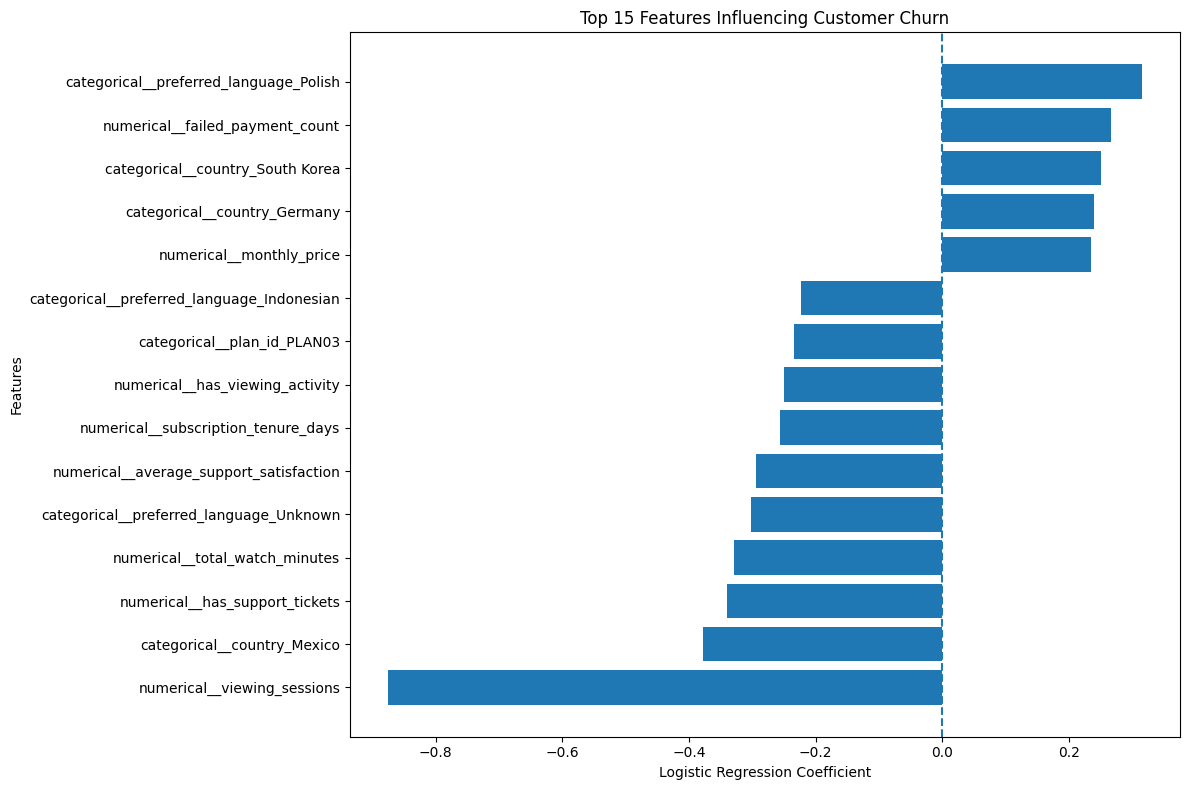

In [14]:
# Select top 15 features
top_features = feature_importance.head(15).copy()

# Sort for chart display
top_features = top_features.sort_values(
    by="Coefficient",
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(12, 8))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(x=0, linestyle="--")

plt.title("Top 15 Features Influencing Customer Churn")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## 13. Feature Importance Visualization

### Objective
To visualize the strongest features influencing the Logistic Regression model's churn predictions.

### Key Findings
- Viewing sessions has the strongest negative coefficient.
- Preferred language (Polish) has the strongest positive coefficient.
- Failed payment count and monthly price have positive coefficients.
- Total watch minutes and support satisfaction have negative coefficients.

### Interpretation
The chart indicates that customer engagement and support-related features are associated with lower predicted churn, while failed payments and higher monthly prices are associated with higher predicted churn.

### Conclusion
The feature importance visualization makes the model's predictions easier to interpret and highlights useful areas for customer retention analysis. These are model associations, not proof of causation.

In [15]:
import joblib
import os

# Select the trained Logistic Regression pipeline
final_model = pipelines["Logistic Regression"]

# Save the model
model_path = "/content/netflix_churn_model.pkl"
joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)
print("Selected threshold:", best_threshold)

Model saved successfully!
Saved location: /content/netflix_churn_model.pkl
Selected threshold: 0.6


In [16]:
import json

threshold_path = "/content/netflix_churn_threshold.json"

threshold_config = {
    "model": "Logistic Regression",
    "churn_threshold": best_threshold
}

with open(threshold_path, "w") as file:
    json.dump(threshold_config, file, indent=4)

print("Threshold configuration saved successfully!")
print("Saved location:", threshold_path)

Threshold configuration saved successfully!
Saved location: /content/netflix_churn_threshold.json


In [17]:
import joblib
import json

# Load the saved model
loaded_model = joblib.load("/content/netflix_churn_model.pkl")

# Load the saved threshold
with open("/content/netflix_churn_threshold.json", "r") as file:
    loaded_config = json.load(file)

loaded_threshold = loaded_config["churn_threshold"]

# Predict using one customer from the test dataset
sample_customer = X_test.iloc[[0]]

churn_probability = loaded_model.predict_proba(sample_customer)[0][1]

churn_prediction = int(churn_probability >= loaded_threshold)

print("Model loaded successfully!")
print("Churn probability:", round(churn_probability, 4))
print("Selected threshold:", loaded_threshold)
print("Prediction:", "Likely to Churn" if churn_prediction == 1 else "Not Likely to Churn")

Model loaded successfully!
Churn probability: 0.6852
Selected threshold: 0.6
Prediction: Likely to Churn


## 14. Model Saving and Prediction Testing

### Objective
To save the trained Logistic Regression pipeline and prediction threshold for future use.

### Implementation
- Saved the complete model pipeline using Joblib.
- Saved the selected prediction threshold (0.60) in a JSON file.
- Reloaded both saved files.
- Tested the model using one customer record from the test dataset.

### Test Result
- Churn probability: 0.6852
- Selected threshold: 0.60
- Predicted result: Likely to Churn

### Conclusion
The saved model loaded successfully and generated a prediction. This confirms that the model and preprocessing pipeline can be reused without retraining.

# 15. Overall Model Performance Summary

## Objective
To compare the three machine learning models and select a suitable model for customer churn prediction.

## Models Trained
1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

## Model Comparison

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 72.31% | 46.33% | 71.36% | 56.18% | 78.91% |
| Decision Tree | 69.94% | 39.65% | 39.95% | 39.80% | 59.91% |
| Random Forest | 78.75% | 62.08% | 37.44% | 46.71% | 77.72% |

## Selected Model
Logistic Regression was selected as the primary churn detection model because it achieved the highest recall and F1-score among the three models at the default 0.50 threshold.

A threshold of 0.60 was selected after comparing different thresholds. At this threshold, the model achieved:
- Accuracy: 77%
- Precision: 53%
- Recall: 61%
- F1-score: 57%

## Key Findings
- Logistic Regression identified more actual churn customers than the other models at the default threshold.
- Random Forest achieved the highest accuracy and precision but missed more churn customers.
- Decision Tree showed the weakest overall performance.
- Viewing sessions, payment failures, monthly price, and customer support-related features were among the important model inputs.

## Conclusion
The Logistic Regression model provides a useful starting point for identifying customers who may be at risk of churn. Its predictions can support customer retention analysis and help businesses prioritize customers for further investigation.

# 16. Model Limitations and Future Improvements

## Limitations
1. The dataset contains an imbalance between churned and non-churned customers.
2. The prediction threshold was selected using test-set results, so the reported final performance may be optimistic.
3. Some customer information and activity records are missing or imputed.
4. Records occurring on the same date as churn may introduce timing-related data leakage.
5. Model associations do not prove that a feature causes customer churn.
6. The model has been tested on the available dataset but has not yet been validated in a live production environment.

## Future Improvements
- Use a separate validation dataset for threshold selection.
- Perform cross-validation and hyperparameter tuning.
- Test additional models such as XGBoost and LightGBM.
- Apply SHAP for more detailed model explanations.
- Validate the model using newer customer data.
- Integrate the model into a Streamlit dashboard and AI analytics copilot.

## Final Conclusion
This phase successfully developed, evaluated, saved, and tested machine learning models for predicting customer churn. The selected Logistic Regression pipeline can be reused in the next project phases, subject to further validation and improvements.